## Importation des Bibliothèques

In [2]:
#%pip install numpy pandas matplotlib pillow scikit-learn tensorflow kagglehub keras-tuner seaborn

In [72]:
import os
import gc
from sklearn.model_selection import train_test_split
import glob
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
import keras_tuner as kt
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, classification_report,ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

## Configuration des Chemins et des Hyperparamètres

In [4]:
CLASSES = ['NORMAL', 'PNEUMONIA']

PATH = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

TRAIN_DIR = os.path.join(PATH, "chest_xray", "chest_xray", "train")
VAL_DIR = os.path.join(PATH, "chest_xray", "chest_xray", "val")
TEST_DIR = os.path.join(PATH, "chest_xray", "chest_xray", "test")

MODEL_DIR = '../models'
BEST_MODEL_PATH = os.path.join(MODEL_DIR, 'best_model.keras')

TUNER_DIR = "../tuner_results"
PROJECT_NAME = "mobilenetv2_transfer_tuning"

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 200

print("Train :", TRAIN_DIR)
print("Val :", VAL_DIR)
print("Test :", TEST_DIR)
print("Model :", BEST_MODEL_PATH)

100%|██████████| 2.29G/2.29G [02:22<00:00, 17.3MB/s]

Extracting files...


Train : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/chest_xray/train
Val : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/chest_xray/val
Test : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/chest_xray/test
Model : ../models/best_model.keras


## Chargement des Datasets (Train, Val, Test)

In [5]:
# train_ds = tf.keras.utils.image_dataset_from_directory(
#     TRAIN_DIR,
#     labels="inferred",
#     label_mode="binary",
#     class_names=CLASSES,
#     color_mode="rgb",
#     batch_size=BATCH_SIZE,
#     image_size=IMG_SIZE,
#     validation_split=0.2,
#     subset="training",
#     seed=SEED,
#     shuffle=True
# )

# val_ds = tf.keras.utils.image_dataset_from_directory(
#     TRAIN_DIR,
#     labels="inferred",
#     label_mode="binary",
#     class_names=CLASSES,
#     color_mode="rgb",
#     batch_size=BATCH_SIZE,
#     image_size=IMG_SIZE,
#     validation_split=0.2,
#     subset="validation",
#     seed=SEED,
#     shuffle=False
# )

# test_ds = tf.keras.utils.image_dataset_from_directory(
#     TEST_DIR,
#     labels="inferred",
#     label_mode="binary",
#     class_names=CLASSES,
#     color_mode="rgb",
#     batch_size=BATCH_SIZE,
#     image_size=IMG_SIZE,
#     shuffle=False
# )

## Définition de la fonction de chargement des images

In [6]:
def load_images(dir_path, classes=CLASSES, img_size=IMG_SIZE):
    images_list = []
    labels_list = []

    for label_idx, cls_name in enumerate(classes):
        cls_dir = os.path.join(dir_path, cls_name)
        file_paths = glob.glob(os.path.join(cls_dir, "*.*"))

        for file_path in file_paths:
            try:
                with Image.open(file_path) as img:
                    img_rgb = img.convert("RGB")
                    img_resized = img_rgb.resize((img_size[1], img_size[0]))
                    img_array = np.asarray(img_resized, dtype=np.uint8)

                images_list.append(img_array)
                labels_list.append(label_idx)

            except Exception:
                pass

    X_data = np.array(images_list)
    y_data = np.asarray(labels_list, dtype=np.float32)

    return X_data, y_data

## Chargement, division stratifiée et préparation des jeux de données

In [7]:
# Chargement des images d'entraînement
X_data, y_data = load_images(TRAIN_DIR)

# Division stratifiée : 80% entraînement, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_data, y_data, test_size=0.2, random_state=SEED, stratify=y_data
)

print("\nImages d'entraînement :", len(X_train))
print("Images de validation :", len(X_val))

# Création du jeu de données d'entraînement
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))

train_ds = (
    train_ds.shuffle(len(X_train), seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Création du jeu de données de validation
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))

val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Chargement des données de test
X_test, y_test = load_images(TEST_DIR)

test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))

test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)



Images d'entraînement : 4172
Images de validation : 1044


I0000 00:00:1792886649.249844    1692 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 31132 MB memory:  -> device: 0, name: Tesla V100-PCIE-32GB, pci bus id: 0000:85:00.0, compute capability: 7.0


## Vérification de la répartition des données

In [8]:
def get_class_counts(y_array, classes=CLASSES):
    unique, counts = np.unique(y_array, return_counts=True)
    counts_dict = dict(zip(unique, counts))
    return {classes[int(k)]: int(v) for k, v in counts_dict.items()}


train_counts = get_class_counts(y_train)
val_counts = get_class_counts(y_val)
test_counts = get_class_counts(y_test)

print(f"data/train : {train_counts} -> total {sum(train_counts.values())}")
print(f"data/val   : {val_counts} -> total {sum(val_counts.values())}")
print(f"data/test  : {test_counts} -> total {sum(test_counts.values())}")

data/train : {'NORMAL': 1073, 'PNEUMONIA': 3099} -> total 4172
data/val   : {'NORMAL': 268, 'PNEUMONIA': 776} -> total 1044
data/test  : {'NORMAL': 234, 'PNEUMONIA': 390} -> total 624


## Création des sous-ensembles réduits (Subset 30%)

In [9]:
sample_rate = 0.3

train_batches = len(train_ds)
val_batches = len(val_ds)

small_train_ds = train_ds.take(max(1, int(train_batches * sample_rate)))
small_val_ds = val_ds.take(max(1, int(val_batches * sample_rate)))

## Gestion du déséquilibre des classes (Class Weighting)

In [10]:
classes_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = dict(enumerate(classes_weights))
print("Class weights :", class_weight_dict)

Class weights : {0: np.float64(1.9440820130475303), 1: np.float64(0.6731203614069055)}


## Data Augmentation

In [11]:
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.01),
    layers.RandomZoom(0.05),
    layers.RandomBrightness(factor=0.05),
    layers.RandomContrast(factor=0.05),
], name="data_augmentation")

## Configuration des Callbacks

In [12]:
callbacks_list = [
    EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=True
    )
]

## Initialisation de MobileNetV2 pré-entraîné

In [13]:
feature_extractor = keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,),
        include_top=False,
        weights="imagenet"
    )

feature_extractor.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## Construction du classificateur par Feature Extraction

In [14]:
def build_feature_extraction_model(hp):
    inputs = keras.Input(shape=IMG_SIZE + (3,))

    x = data_augmentation(inputs)
    x = keras.applications.mobilenet_v2.preprocess_input(x)
    x = feature_extractor(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)

    num_dense_layers = hp.Int("num_dense_layers", min_value=1, max_value=3, step=1)

    for i in range(num_dense_layers):
        dense_units = hp.Choice(f"dense_units_{i+1}", values=[64, 128, 256])

        x = layers.Dense(dense_units, activation="relu")(x)

        x = layers.BatchNormalization()(x)

        dropout_rate = hp.Choice(f"dropout_{i+1}", values=[0.2, 0.3, 0.5])

        x = layers.Dropout(dropout_rate)(x)

    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, outputs, name="MobileNetV2_Feature_Extraction")

    optimizer_name = hp.Choice("optimizer", values=["adam", "sgd"])

    if optimizer_name == "adam":
        learning_rate = hp.Choice("learning_rate_adam", values=[0.0001, 0.0003, 0.001])
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    else:
        learning_rate = hp.Choice("learning_rate_sgd", values=[0.001, 0.005, 0.01])
        momentum = hp.Choice("momentum", values=[0.8, 0.9, 0.95])
        optimizer = keras.optimizers.SGD(learning_rate=learning_rate, momentum=momentum)

    model.compile(
        optimizer=optimizer,
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc"),
        ],
    )

    return model

## Optimisation des hyperparamètres par Bayesian Optimization

In [ ]:
feature_extraction_tuner = kt.BayesianOptimization(
    hypermodel=build_feature_extraction_model,
    objective=kt.Objective("val_loss", direction="min"),
    max_trials=30,
    executions_per_trial=1,
    directory=TUNER_DIR,
    project_name="chestscan_feature_extraction",
    overwrite=True
)


## Entraînement et recherche des meilleurs hyperparamètres

In [16]:
feature_extraction_tuner.search(
    small_train_ds,
    validation_data=small_val_ds,
    epochs=10,
    callbacks=callbacks_list,
    class_weight=class_weight_dict
)

Trial 30 Complete [00h 00m 24s]
val_loss: 0.08652419596910477

Best val_loss So Far: 0.07520812004804611
Total elapsed time: 00h 12m 20s


## Affichage des meilleurs hyperparamètres

In [17]:
best_hp_feature_extraction = feature_extraction_tuner.get_best_hyperparameters(num_trials=1)[0]

print("Meilleurs hyperparamètres :")
for name, value in best_hp_feature_extraction.values.items():
    print(f"- {name}: {value}")

Meilleurs hyperparamètres :
- num_dense_layers: 3
- dense_units_1: 256
- dropout_1: 0.5
- optimizer: adam
- learning_rate_adam: 0.001
- dense_units_2: 128
- dropout_2: 0.3
- dense_units_3: 256
- dropout_3: 0.2
- learning_rate_sgd: 0.005
- momentum: 0.9


## Construction du modèle avec les meilleurs hyperparamètres

In [18]:
feature_extraction_model = build_feature_extraction_model(best_hp_feature_extraction)

## Entraînement complet du modèle final

In [19]:
history_feature_extraction = feature_extraction_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_list,
    class_weight=class_weight_dict
)

Epoch 1/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - accuracy: 0.7885 - auc: 0.9112 - loss: 0.3937 - precision: 0.9454 - recall: 0.7518 - val_accuracy: 0.9540 - val_auc: 0.9871 - val_loss: 0.1375 - val_precision: 0.9461 - val_recall: 0.9948
Epoch 2/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.9345 - auc: 0.9831 - loss: 0.1702 - precision: 0.9826 - recall: 0.9278 - val_accuracy: 0.9684 - val_auc: 0.9936 - val_loss: 0.0908 - val_precision: 0.9673 - val_recall: 0.9910
Epoch 3/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.9481 - auc: 0.9863 - loss: 0.1481 - precision: 0.9813 - recall: 0.9481 - val_accuracy: 0.9693 - val_auc: 0.9942 - val_loss: 0.0731 - val_precision: 0.9781 - val_recall: 0.9807
Epoch 4/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.9526 - auc: 0.9889 - loss: 0.1322 - precision: 0.9863 - recall: 0.9496 - val_accuracy: 0.9703 - val_auc: 0.9938 - val_loss: 0.0752 - val_precision: 0.9745 - val_recall: 0.9858
Epoch 5/200
131/131 ━━━

## Évaluation du modèle sur le jeu d'entraînement et de validation

In [20]:
train_results = feature_extraction_model.evaluate(train_ds, return_dict=True)
val_results = feature_extraction_model.evaluate(val_ds, return_dict=True)

df_comparison = pd.DataFrame({
    "Training": train_results,
    "Validation": val_results
})

display(df_comparison.round(4))

131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9825 - auc: 0.9985 - loss: 0.0496 - precision: 0.9909 - recall: 0.9853
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9758 - auc: 0.9962 - loss: 0.0698 - precision: 0.9874 - recall: 0.9798


,Training,Validation
accuracy,0.9813,0.9780
auc,0.9978,0.9967
loss,0.0558,0.0616
precision,0.9915,0.9871
recall,0.9832,0.9832


## Courbes d'apprentissage (Loss et Metrics)

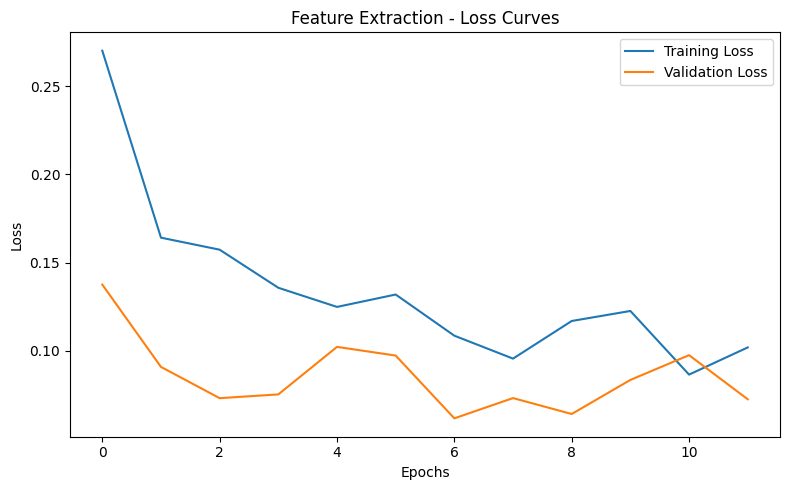

In [21]:
plt.figure(figsize=(8, 5))
plt.plot(history_feature_extraction.history["loss"], label="Training Loss")
plt.plot(history_feature_extraction.history["val_loss"], label="Validation Loss")
plt.title("Feature Extraction - Loss Curves")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

## Matrice de confusion — Validation

2026-10-25 00:17:57.620332: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


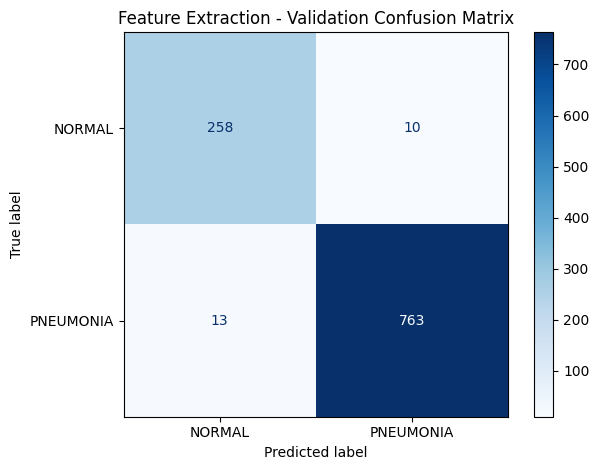

              precision    recall  f1-score   support

      NORMAL       0.95      0.96      0.96       268
   PNEUMONIA       0.99      0.98      0.99       776

    accuracy                           0.98      1044
   macro avg       0.97      0.97      0.97      1044
weighted avg       0.98      0.98      0.98      1044



In [22]:
y_val_true = np.concatenate([y.numpy() for _, y in val_ds], axis=0).ravel()
y_val_probs_fe = feature_extraction_model.predict(val_ds, verbose=0).ravel()
y_val_pred_fe = (y_val_probs_fe >= 0.5).astype(int)

cm_val_fe = confusion_matrix(y_val_true, y_val_pred_fe)

display_cm_fe = ConfusionMatrixDisplay(
    confusion_matrix=cm_val_fe,
    display_labels=CLASSES
)

display_cm_fe.plot(cmap="Blues")
plt.title("Feature Extraction - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(y_val_true, y_val_pred_fe, target_names=CLASSES))

## Dégel des couches supérieures du modèle de base

In [24]:
# feature_extractor.trainable = True

# for layer in feature_extractor.layers[:-50]:
#     layer.trainable = False

# for layer in feature_extractor.layers[-50:]:
#     if isinstance(layer, layers.BatchNormalization):
#         layer.trainable = False

## Construction de la fonction du modèle pour le Fine-Tuning

In [25]:
def build_fine_tuning_model(hp):
    inputs = keras.Input(shape=IMG_SIZE + (3,))

    x = data_augmentation(inputs)
    x = keras.applications.mobilenet_v2.preprocess_input(x)

    base_model = keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet"
    )

    unfreeze_layers = hp.Choice("unfreeze_layers", values=[10, 20, 30])
    base_model.trainable = True

    for layer in base_model.layers[:-unfreeze_layers]:
        layer.trainable = False

    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)

    num_dense_layers = hp.Int("num_dense_layers", min_value=1, max_value=2, step=1)

    for i in range(num_dense_layers):
        dense_units = hp.Choice(f"dense_units_{i+1}", values=[64, 128])
        x = layers.Dense(
            dense_units,
            activation="relu",
            kernel_regularizer=keras.regularizers.l2(1e-4),
        )(x)
        dropout_rate = hp.Choice(f"dropout_{i+1}", values=[0.3, 0.4, 0.5])
        x = layers.Dropout(dropout_rate)(x)

    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs, name="MobileNetV2_Fine_Tuning")

    learning_rate = hp.Choice("fine_tuning_lr", values=[1e-5, 2e-5, 3e-5])
    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc"),
        ],
    )

    return model

## Optimisation des hyperparamètres par Bayesian Optimization

In [26]:
fine_tuning_tuner = kt.BayesianOptimization(
    hypermodel=build_fine_tuning_model,
    objective=kt.Objective("val_loss", direction="min"),
    max_trials=30,
    executions_per_trial=1,
    directory=TUNER_DIR,
    project_name="chestscan_fine_tuning",
    overwrite=True
)

## Entraînement et recherche des meilleurs hyperparamètres

In [27]:
reduce_lr_callback = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

In [28]:
fine_tuning_tuner.search(
    small_train_ds,
    validation_data=small_val_ds,
    epochs=10,
    callbacks=callbacks_list + [reduce_lr_callback],
    class_weight=class_weight_dict
)

Trial 30 Complete [00h 00m 33s]
val_loss: 0.0865575447678566

Best val_loss So Far: 0.07615485042333603
Total elapsed time: 00h 15m 43s


## Affichage des meilleurs hyperparamètres

In [29]:
best_hp_fine_tuning = fine_tuning_tuner.get_best_hyperparameters(num_trials=1)[0]

print("Meilleurs hyperparamètres — Fine-Tuning :")

for name, value in best_hp_fine_tuning.values.items():
    print(f"{name}: {value}")

Meilleurs hyperparamètres — Fine-Tuning :
unfreeze_layers: 30
num_dense_layers: 1
dense_units_1: 64
dropout_1: 0.3
fine_tuning_lr: 3e-05
dense_units_2: 64
dropout_2: 0.4


## Construction du modèle Fine-Tuning avec les meilleurs hyperparamètres

In [30]:
fine_tuning_model = build_fine_tuning_model(best_hp_fine_tuning)

## Entraînement complet du modèle Fine-Tuning

In [31]:
history_fine_tuning = fine_tuning_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_list + [reduce_lr_callback],
    class_weight=class_weight_dict
)

Epoch 1/200


131/131 ━━━━━━━━━━━━━━━━━━━━ 11s 49ms/step - accuracy: 0.8722 - auc: 0.9225 - loss: 0.3312 - precision: 0.9461 - recall: 0.8822 - val_accuracy: 0.9703 - val_auc: 0.9938 - val_loss: 0.0971 - val_precision: 0.9697 - val_recall: 0.9910 - learning_rate: 3.0000e-05
Epoch 2/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.9598 - auc: 0.9944 - loss: 0.1077 - precision: 0.9902 - recall: 0.9555 - val_accuracy: 0.9646 - val_auc: 0.9954 - val_loss: 0.1020 - val_precision: 0.9894 - val_recall: 0.9626 - learning_rate: 3.0000e-05
Epoch 3/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.9683 - auc: 0.9947 - loss: 0.0960 - precision: 0.9923 - recall: 0.9648 - val_accuracy: 0.9741 - val_auc: 0.9953 - val_loss: 0.0766 - val_precision: 0.9883 - val_recall: 0.9768 - learning_rate: 3.0000e-05
Epoch 4/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.9837 - auc: 0.9974 - loss: 0.0660 - precision: 0.9961 - recall: 0.9817 - val_accuracy: 0.9808 - val_auc: 0.9964 - val_loss: 0.0

## Affichage des courbes d'apprentissage (Loss Curves - Fine-Tuning)

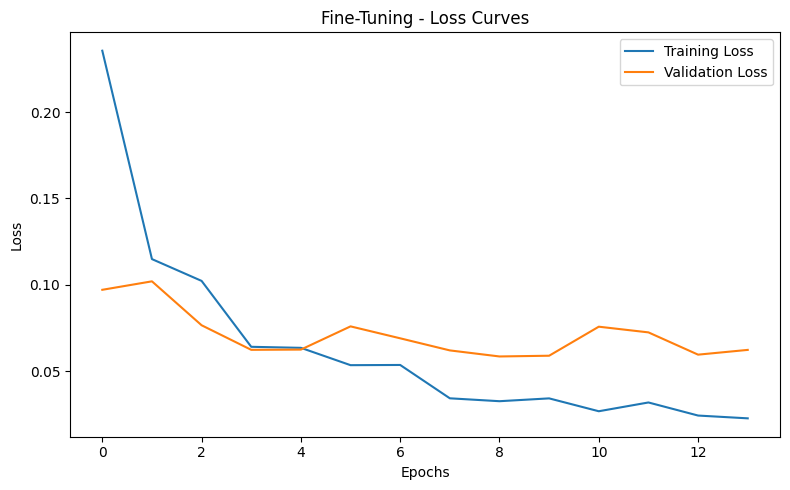

In [32]:
plt.figure(figsize=(8, 5))
plt.plot(history_fine_tuning.history["loss"], label="Training Loss")
plt.plot(history_fine_tuning.history["val_loss"], label="Validation Loss")
plt.title("Fine-Tuning - Loss Curves")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

## Évaluation du modèle sur le jeu d'entraînement et de validation

In [33]:
train_results = fine_tuning_model.evaluate(train_ds, return_dict=True)
val_results = fine_tuning_model.evaluate(val_ds, return_dict=True)

df_comparison = pd.DataFrame({
    "Training": train_results,
    "Validation": val_results
})

display(df_comparison.round(4))

131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9962 - auc: 0.9999 - loss: 0.0217 - precision: 0.9984 - recall: 0.9965
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9771 - auc: 0.9962 - loss: 0.0621 - precision: 0.9825 - recall: 0.9867


,Training,Validation
accuracy,0.9950,0.9808
auc,0.9999,0.9952
loss,0.0243,0.0585
precision,0.9968,0.9859
recall,0.9965,0.9884


## Matrice de confusion — Validation

2026-10-25 00:35:06.922074: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


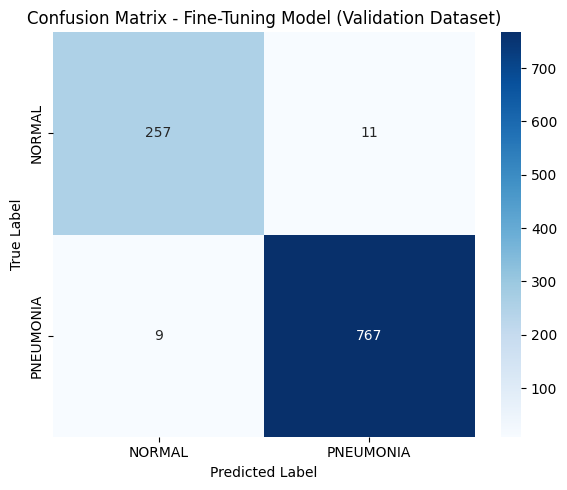

              precision    recall  f1-score   support

      NORMAL       0.97      0.96      0.96       268
   PNEUMONIA       0.99      0.99      0.99       776

    accuracy                           0.98      1044
   macro avg       0.98      0.97      0.97      1044
weighted avg       0.98      0.98      0.98      1044



In [34]:
y_val_true = np.concatenate([y.numpy() for _, y in val_ds], axis=0).ravel()
y_val_pred_probs_ft = fine_tuning_model.predict(val_ds, verbose=0).ravel()
y_val_pred_ft = (y_val_pred_probs_ft >= 0.5).astype(int)

cm_val_ft = confusion_matrix(y_val_true, y_val_pred_ft)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_val_ft,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.title("Confusion Matrix - Fine-Tuning Model (Validation Dataset)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

print(classification_report(y_val_true, y_val_pred_ft, target_names=CLASSES))

## Construction du classificateur CNN from scratch avec

In [59]:
def build_custom_cnn_model(hp):
    model = keras.Sequential(name="chestscan_cnn")

    model.add(keras.Input(shape=IMG_SIZE + (3,)))
    model.add(data_augmentation)
    model.add(layers.Rescaling(1.0 / 255.0))

    num_conv_blocks = hp.Int("num_conv_blocks", min_value=3, max_value=4, step=1)

    for i in range(num_conv_blocks):
        filters = hp.Choice(f"filters_{i+1}", values=[32, 64, 128, 256])

        model.add(
            layers.Conv2D(
                filters=filters, kernel_size=(3, 3), padding="same", use_bias=False
            )
        )
        model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        model.add(layers.MaxPooling2D(pool_size=(2, 2)))
        model.add(
            layers.Dropout(hp.Choice(f"conv_dropout_{i+1}", values=[0.1, 0.2]))
        )

    model.add(layers.Flatten())

    num_dense_layers = hp.Int("num_dense_layers", min_value=1, max_value=2, step=1)

    for i in range(num_dense_layers):
        units = hp.Choice(f"dense_units_{i+1}", values=[128, 256])

        model.add(
            layers.Dense(
                units, 
                use_bias=False,
                kernel_regularizer=keras.regularizers.l2(1e-4)
            )
        )
        model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))

        dropout_rate = hp.Choice(f"dense_dropout_{i+1}", values=[0.2, 0.3, 0.4])
        model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(1, activation="sigmoid"))

    learning_rate = hp.Choice("learning_rate", values=[0.0001, 0.0003, 0.0005])
    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc"),
        ],
    )

    return model

## Callbacks d'entraînement pour le modèle Custom CNN

In [60]:
callbacks_list_cnn = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3, 
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

## Configuration et Lancement de la Recherche KerasTuner

In [61]:
cnn_tuner = kt.BayesianOptimization(
    hypermodel=build_custom_cnn_model,
    objective=kt.Objective("val_loss", direction="min"),
    max_trials=30,
    executions_per_trial=1,
    directory=TUNER_DIR,
    project_name = "chestscan_cnn_from_scratch",
    overwrite=True,
)

cnn_tuner.search(
    small_train_ds,
    validation_data=small_val_ds,
    epochs=10,
    callbacks=callbacks_list_cnn,
    class_weight=class_weight_dict,
)

Trial 30 Complete [00h 00m 38s]
val_loss: 0.7501637935638428

Best val_loss So Far: 0.6310091614723206
Total elapsed time: 00h 19m 23s


## Affichage des meilleurs hyperparamètres

In [64]:
best_hp_cnn = cnn_tuner.get_best_hyperparameters(num_trials=1)[0]

print("Meilleurs hyperparamètres — Custom CNN :")
for name, value in best_hp_cnn.values.items():
    print(f"{name}: {value}")

Meilleurs hyperparamètres — Custom CNN :
num_conv_blocks: 4
filters_1: 128
conv_dropout_1: 0.2
filters_2: 32
conv_dropout_2: 0.1
filters_3: 32
conv_dropout_3: 0.1
num_dense_layers: 2
dense_units_1: 128
dense_dropout_1: 0.3
learning_rate: 0.0005
filters_4: 32
conv_dropout_4: 0.2
dense_units_2: 128
dense_dropout_2: 0.2


## Construction du modèle CNN avec les meilleurs hyperparamètres

In [65]:
cnn_scratch_model = build_custom_cnn_model(best_hp_cnn)

## Entraînement complet du modèle CNN from Scratch

In [66]:
history_cnn_scratch = cnn_scratch_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_list_cnn,
    class_weight=class_weight_dict
)

Epoch 1/200


E0000 00:00:1792894340.441587    1692 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/chestscan_cnn_1/dropout_10_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


131/131 ━━━━━━━━━━━━━━━━━━━━ 20s 131ms/step - accuracy: 0.8304 - auc: 0.9192 - loss: 0.3831 - precision: 0.9451 - recall: 0.8217 - val_accuracy: 0.7433 - val_auc: 0.7070 - val_loss: 1.2321 - val_precision: 0.7433 - val_recall: 1.0000 - learning_rate: 5.0000e-04
Epoch 2/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 16s 126ms/step - accuracy: 0.9376 - auc: 0.9881 - loss: 0.1856 - precision: 0.9853 - recall: 0.9311 - val_accuracy: 0.7433 - val_auc: 0.7387 - val_loss: 1.4054 - val_precision: 0.7433 - val_recall: 1.0000 - learning_rate: 5.0000e-04
Epoch 3/200
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.9564 - auc: 0.9926 - loss: 0.1489 - precision: 0.9908 - recall: 0.9498
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
131/131 ━━━━━━━━━━━━━━━━━━━━ 17s 126ms/step - accuracy: 0.9564 - auc: 0.9926 - loss: 0.1490 - precision: 0.9908 - recall: 0.9498 - val_accuracy: 0.7433 - val_auc: 0.8530 - val_loss: 1.3395 - val_precision: 0.7433 - val_recall: 1.0000 - learning_rat

## Affichage des courbes d'apprentissage (Loss Curves - CNN Scratch)

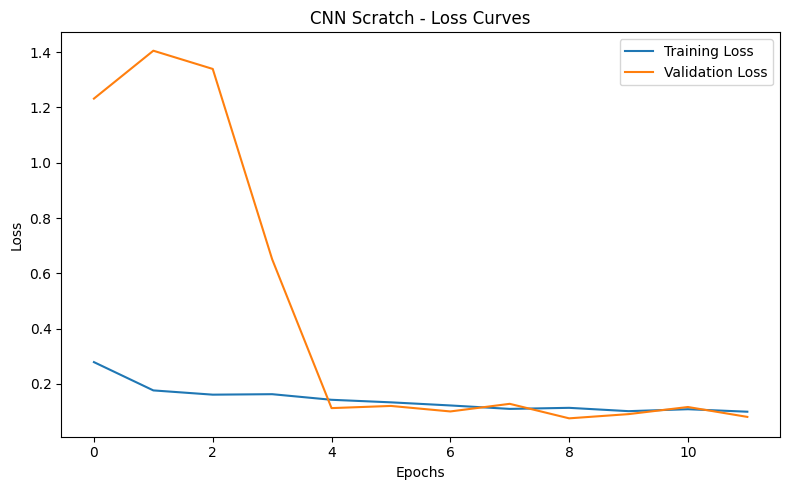

In [67]:
plt.figure(figsize=(8, 5))
plt.plot(history_cnn_scratch.history["loss"], label="Training Loss")
plt.plot(history_cnn_scratch.history["val_loss"], label="Validation Loss")
plt.title("CNN Scratch - Loss Curves")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

## Évaluation du modèle sur le jeu d'entraînement et de validation

In [73]:
train_results = cnn_scratch_model.evaluate(train_ds, return_dict=True)
val_results = cnn_scratch_model.evaluate(val_ds, return_dict=True)

df_comparison = pd.DataFrame({
    "Training": train_results,
    "Validation": val_results
})

display(df_comparison.round(4))

131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9899 - auc: 0.9993 - loss: 0.0708 - precision: 0.9975 - recall: 0.9888
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9859 - auc: 0.9988 - loss: 0.0809 - precision: 0.9927 - recall: 0.9881


,Training,Validation
accuracy,0.9923,0.9866
auc,0.9995,0.9992
loss,0.0665,0.0754
precision,0.9974,0.9922
recall,0.9923,0.9897


## Matrice de confusion — Validation

33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step


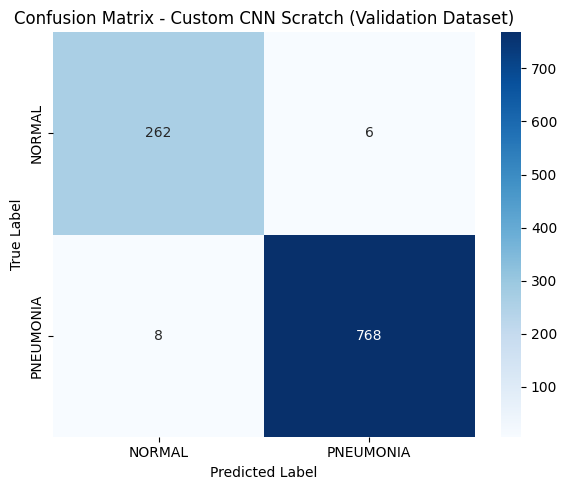

              precision    recall  f1-score   support

      NORMAL       0.97      0.98      0.97       268
   PNEUMONIA       0.99      0.99      0.99       776

    accuracy                           0.99      1044
   macro avg       0.98      0.98      0.98      1044
weighted avg       0.99      0.99      0.99      1044



In [69]:
y_val_true = np.concatenate([y.numpy() for x, y in val_ds], axis=0)
y_val_pred_probs_cnn = cnn_scratch_model.predict(val_ds)
y_val_pred_cnn = (y_val_pred_probs_cnn > 0.5).astype(int)

cm_val_cnn = confusion_matrix(y_val_true, y_val_pred_cnn)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_val_cnn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.title("Confusion Matrix - Custom CNN Scratch (Validation Dataset)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

print(classification_report(y_val_true, y_val_pred_cnn, target_names=CLASSES))

## Définition des modèles

In [98]:
models = {
    "Custom CNN": cnn_scratch_model,
    "Feature Extraction": feature_extraction_model,
    "Fine-Tuning": fine_tuning_model
}

class_names = ["NORMAL", "PNEUMONIA"]

## Évaluation des trois modèles sur le jeu de test

In [99]:
models = {
    "Custom CNN": cnn_scratch_model,
    "Feature Extraction": feature_extraction_model,
    "Fine-Tuning": fine_tuning_model
}

results = {}
y_true = np.concatenate([y.numpy() for _, y in test_ds])

for name, model in models.items():
    y_prob = model.predict(test_ds, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    results[name] = {
        "y_pred": y_pred,
        "y_prob": y_prob,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

metrics_df = pd.DataFrame({
    name: {k: v for k, v in result.items()
           if k not in ["y_pred", "y_prob"]}
    for name, result in results.items()
}).T

display(metrics_df.round(4))

2026-10-25 03:25:03.408036: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Custom CNN,0.7885,0.7500,0.9923,0.8543,0.9174
Feature Extraction,0.8301,0.7898,0.9923,0.8795,0.9559
Fine-Tuning,0.8045,0.7627,0.9974,0.8644,0.9703


## Matrices de confusion des trois modèles

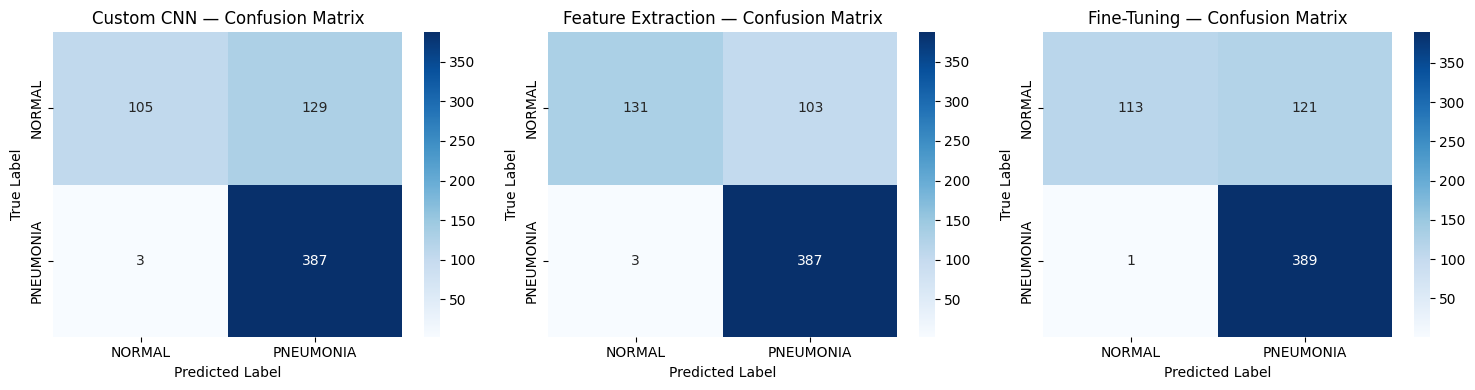

In [100]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, result) in zip(axes, results.items()):
    cm = confusion_matrix(y_true, result["y_pred"])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASSES,
        yticklabels=CLASSES,
        ax=ax,
    )

    ax.set_title(f"{name} — Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()

## Comparaison graphique des performances

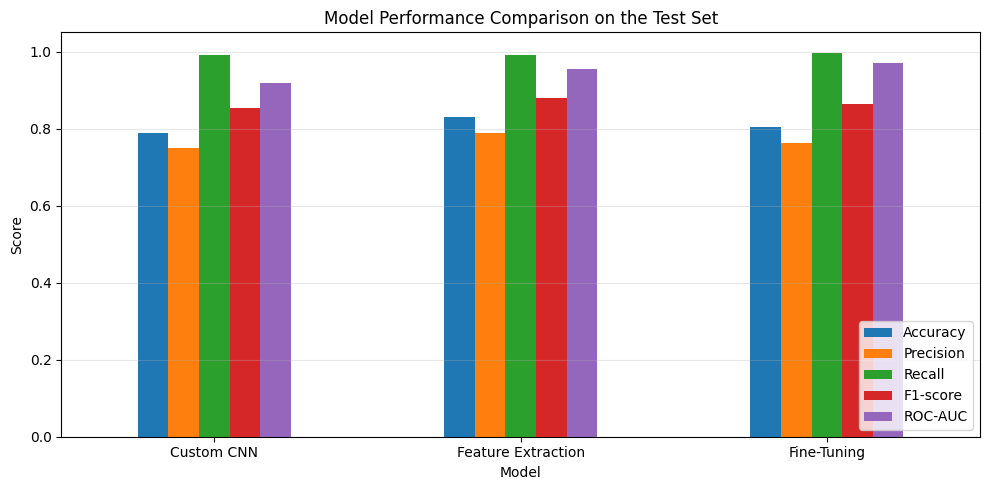

In [101]:
metrics_df.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1.05)
)

plt.title("Model Performance Comparison on the Test Set")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Comparaison du Recall par classe

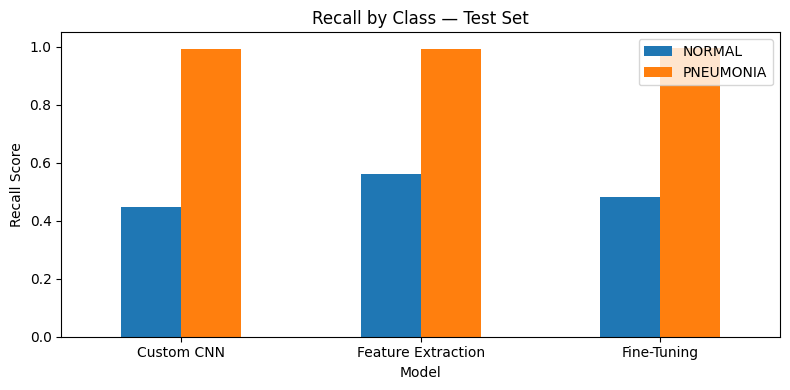

In [102]:
recall_by_class = {}

for name, result in results.items():
    report = classification_report(
        y_true,
        result["y_pred"],
        target_names=CLASSES,
        output_dict=True,
        zero_division=0
    )

    recall_by_class[name] = {
        cls: report[cls]["recall"] for cls in CLASSES
    }

pd.DataFrame(recall_by_class).T.plot(
    kind="bar",
    figsize=(8, 4),
    ylim=(0, 1.05)
)

plt.title("Recall by Class — Test Set")
plt.ylabel("Recall Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Sauvegarde des modèles de Deep Learning entraînés

In [97]:
os.makedirs(MODEL_DIR, exist_ok=True)

cnn_scratch_model.save(
    os.path.join(MODEL_DIR, "cnn_scratch_model.keras")
)

feature_extraction_model.save(
    os.path.join(MODEL_DIR, "feature_extraction_model.keras")
)

fine_tuning_model.save(
    os.path.join(MODEL_DIR, "fine_tuning_model.keras")
)